# Phase 1 & 2: Exploratory Data Analysis (EDA) of IMD Climate Datasets

**Project Title**: AI-Powered Digital Twin of India's Climate using National Datasets  
**Notebook Purpose**: Inspecting spatial-temporal structure, dimensions, coordinate systems, missing values, and baseline statistics of India Meteorological Department (IMD) gridded climate observations (Rainfall, Max Temp, Min Temp).

---

## Section 1: Import Core Libraries
We import standard Python data science and multidimensional geospatial libraries:
- **`xarray`**: Standard Python tool for working with N-dimensional labeled array data (NetCDF).
- **`netCDF4`**: Backend engine for reading network Common Data Form climate files.
- **`numpy` & `pandas`**: Tabular and numerical processing tools.
- **`matplotlib` & `seaborn`**: Plotting and spatial heatmap rendering.

In [1]:
import os
import sys
from pathlib import Path

# Geospatial & Scientific Data Libraries
import xarray as xr
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print

# Set default plot style for climate graphics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Libraries successfully imported!")
print(f"xarray version: {xr.__version__}")
print(f"pandas version: {pd.__version__}")
print(f"numpy version:  {np.__version__}")

Libraries successfully imported!
xarray version: 2026.9.0
pandas version: 3.0.6
numpy version:  2.5.3


## Section 2: Define Project Paths & Central Configurations
We import project path settings from our custom configuration module (`src.data.config`). This keeps data directories dynamic and configurable.

In [2]:
# Add project root to Python module search path
import os, sys
from pathlib import Path
NOTEBOOK_DIR = Path.cwd()
if (NOTEBOOK_DIR / 'src').exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / 'src').exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    PROJECT_ROOT = NOTEBOOK_DIR

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.config import DATASETS, INDIA_BOUNDS, RAW_DATA_DIR, PROCESSED_DATA_DIR, get_dataset_config

print('Project Root Path:', PROJECT_ROOT)
print('Raw Data Directory:', RAW_DATA_DIR)
print('Available Configured Datasets:', list(DATASETS.keys()))
print('India Bounding Box:', INDIA_BOUNDS)

Project Root Path: C:\Users\HP\Desktop\Major Project
Raw Data Directory: C:\Users\HP\Desktop\Major Project\data\raw
Available Configured Datasets: ['rainfall', 'max_temp', 'min_temp']
India Bounding Box: {'min_lat': 6.5, 'max_lat': 38.5, 'min_lon': 68.5, 'max_lon': 97.5}


## Section 3: Load Climate Dataset

> **Note for Phase 1**: Below is a flexible data loading function designed to open IMD NetCDF (`.nc`) or binary (`.grd`) dataset files. Once raw IMD data files are placed into `data/raw/`, update `sample_file_path` to point to the actual file.

In [3]:
# Path placeholder for actual downloaded IMD dataset file (.nc or .grd)
sample_file_path = RAW_DATA_DIR / 'rainfall' / 'sample_rain.nc'

def load_dataset(file_path: Path):
    """Flexibly load a NetCDF or geospatial climate dataset."""
    if not file_path.exists():
        print(f"[NOTE] File not found at: {file_path}")
        print("Creating synthetic xarray dataset for demonstration and structure verification...")
        
        lats = np.arange(INDIA_BOUNDS['min_lat'], INDIA_BOUNDS['max_lat'] + 0.25, 0.25)
        lons = np.arange(INDIA_BOUNDS['min_lon'], INDIA_BOUNDS['max_lon'] + 0.25, 0.25)
        times = pd.date_range('2023-06-01', periods=30, freq='D')
        
        rain_data = np.random.exponential(scale=10.0, size=(len(times), len(lats), len(lons)))
        rain_data[rain_data < 2.0] = 0.0
        rain_data[:, :5, :5] = np.nan
        
        ds = xr.Dataset(
            data_vars={
                'rf': (['time', 'lat', 'lon'], rain_data, {'units': 'mm/day', 'long_name': 'Daily Rainfall'})
            },
            coords={
                'time': times,
                'lat': lats,
                'lon': lons
            },
            attrs={
                'title': 'IMD Synthetic Gridded Rainfall Dataset (POC Demonstration)',
                'spatial_resolution': '0.25 deg x 0.25 deg',
                'source': 'India Meteorological Department (IMD) Structure Prototype'
            }
        )
        return ds
    else:
        return xr.open_dataset(file_path)

ds = load_dataset(sample_file_path)
print("Dataset successfully loaded!")

[NOTE] File not found at: C:\Users\HP\Desktop\Major Project\data\raw\rainfall\sample_rain.nc
Creating synthetic xarray dataset for demonstration and structure verification...
Dataset successfully loaded!


## Section 4: Inspect Dataset Structure
We print the overall high-level `xarray` dataset representation, including global metadata attributes.

In [4]:
print("=== Dataset High-Level Overview ===")
display(ds)

=== Dataset High-Level Overview ===


<xarray.Dataset> Size: 4MB
Dimensions:  (time: 30, lat: 129, lon: 117)
Coordinates:
  * time     (time) datetime64[us] 240B 2023-06-01 2023-06-02 ... 2023-06-30
  * lat      (lat) float64 1kB 6.5 6.75 7.0 7.25 7.5 ... 37.75 38.0 38.25 38.5
  * lon      (lon) float64 936B 68.5 68.75 69.0 69.25 ... 96.75 97.0 97.25 97.5
Data variables:
    rf       (time, lat, lon) float64 4MB nan nan nan nan ... 5.324 2.804 0.0
Attributes:
    title:               IMD Synthetic Gridded Rainfall Dataset (POC Demonstr...
    spatial_resolution:  0.25 deg x 0.25 deg
    source:              India Meteorological Department (IMD) Structure Prot...

## Section 5: Display Dimensions
Inspect the dimension names and sizes (e.g., number of time steps, latitude grid points, longitude grid points).

In [5]:
print("=== Dataset Dimensions ===")
for dim_name, dim_size in ds.sizes.items():
    print(f"Dimension: {dim_name:<10} | Size: {dim_size}")

=== Dataset Dimensions ===
Dimension: time       | Size: 30
Dimension: lat        | Size: 129
Dimension: lon        | Size: 117


## Section 6: Display Variables & Metadata Attributes
Identify data variables (e.g., `rf`, `rain`, `tmax`, `tmin`) and their associated units or descriptions.

In [6]:
print("=== Data Variables ===")
for var_name, var_data in ds.data_vars.items():
    print(f"Variable Name: {var_name}")
    print(f"  Shape:        {var_data.shape}")
    print(f"  Data Type:    {var_data.dtype}")
    print(f"  Attributes:   {var_data.attrs}")

=== Data Variables ===
Variable Name: rf
  Shape:        (30, 129, 117)
  Data Type:    float64
  Attributes:   {'units': 'mm/day', 'long_name': 'Daily Rainfall'}


## Section 7: Check Latitude & Longitude Coordinate Alignment
Inspect spatial coordinate bounds and step sizes to confirm spatial alignment across the Indian region.

In [7]:
lat_var = 'lat' if 'lat' in ds.coords else 'latitude'
lon_var = 'lon' if 'lon' in ds.coords else 'longitude'

lats = ds.coords[lat_var].values
lons = ds.coords[lon_var].values

print("=== Latitude Coordinate Inspection ===")
print(f"  Min Latitude: {lats.min():.2f} deg N | Max Latitude: {lats.max():.2f} deg N")
print(f"  Lat Grid Resolution (Step): {np.abs(np.diff(lats)).mean():.4f} deg")

print("\n=== Longitude Coordinate Inspection ===")
print(f"  Min Longitude: {lons.min():.2f} deg E | Max Longitude: {lons.max():.2f} deg E")
print(f"  Lon Grid Resolution (Step): {np.abs(np.diff(lons)).mean():.4f} deg")

=== Latitude Coordinate Inspection ===
  Min Latitude: 6.50 deg N | Max Latitude: 38.50 deg N
  Lat Grid Resolution (Step): 0.2500 deg

=== Longitude Coordinate Inspection ===
  Min Longitude: 68.50 deg E | Max Longitude: 97.50 deg E
  Lon Grid Resolution (Step): 0.2500 deg


## Section 8: Check Time Dimension
Verify start date, end date, sampling frequency (daily/monthly), and total timestep count.

In [8]:
time_var = 'time' if 'time' in ds.coords else 'TIME'
times = ds.coords[time_var].values

print("=== Time Dimension Inspection ===")
print(f"  Start Date: {pd.to_datetime(times[0]).strftime('%Y-%m-%d')}")
print(f"  End Date:   {pd.to_datetime(times[-1]).strftime('%Y-%m-%d')}")
print(f"  Total Timesteps: {len(times)}")

=== Time Dimension Inspection ===
  Start Date: 2023-06-01
  End Date:   2023-06-30
  Total Timesteps: 30


## Section 9: Check Missing Values & Invalid Mask Values
IMD grids often contain fill values (e.g., `-999.0` or `NaN`) for ocean grid cells or non-reporting land stations. We measure missing value ratios.

In [9]:
main_var = list(ds.data_vars.keys())[0]
var_array = ds[main_var].values

var_array_clean = np.where(var_array == -999.0, np.nan, var_array)
nan_count = np.isnan(var_array_clean).sum()
total_count = var_array_clean.size
nan_percentage = (nan_count / total_count) * 100

print(f"=== Missing Value Analysis for '{main_var}' ===")
print(f"  Total Grid Elements:  {total_count:,}")
print(f"  NaN / Masked Elements:{nan_count:,}")
print(f"  Missing Percentage:   {nan_percentage:.2f}%")

=== Missing Value Analysis for 'rf' ===
  Total Grid Elements:  452,790
  NaN / Masked Elements:750
  Missing Percentage:   0.17%


## Section 10: Calculate Basic Statistical Summaries
Compute summary statistics across non-NaN climate grid cells.

In [10]:
valid_data = var_array_clean[~np.isnan(var_array_clean)]

print(f"=== Summary Statistics for '{main_var}' ===")
print(f"  Mean:   {np.mean(valid_data):.2f}")
print(f"  Std:    {np.std(valid_data):.2f}")
print(f"  Min:    {np.min(valid_data):.2f}")
print(f"  25%:    {np.percentile(valid_data, 25):.2f}")
print(f"  50% (Median): {np.median(valid_data):.2f}")
print(f"  75%:    {np.percentile(valid_data, 75):.2f}")
print(f"  Max:    {np.max(valid_data):.2f}")

=== Summary Statistics for 'rf' ===
  Mean:   9.83
  Std:    10.15
  Min:    0.00
  25%:    2.89
  50% (Median): 6.92
  75%:    13.89
  Max:    118.40


## Section 11: Initial Visualization & Spatial Heatmap Plotting
Render spatial heatmaps and time-series line plots of the climate variable across India.

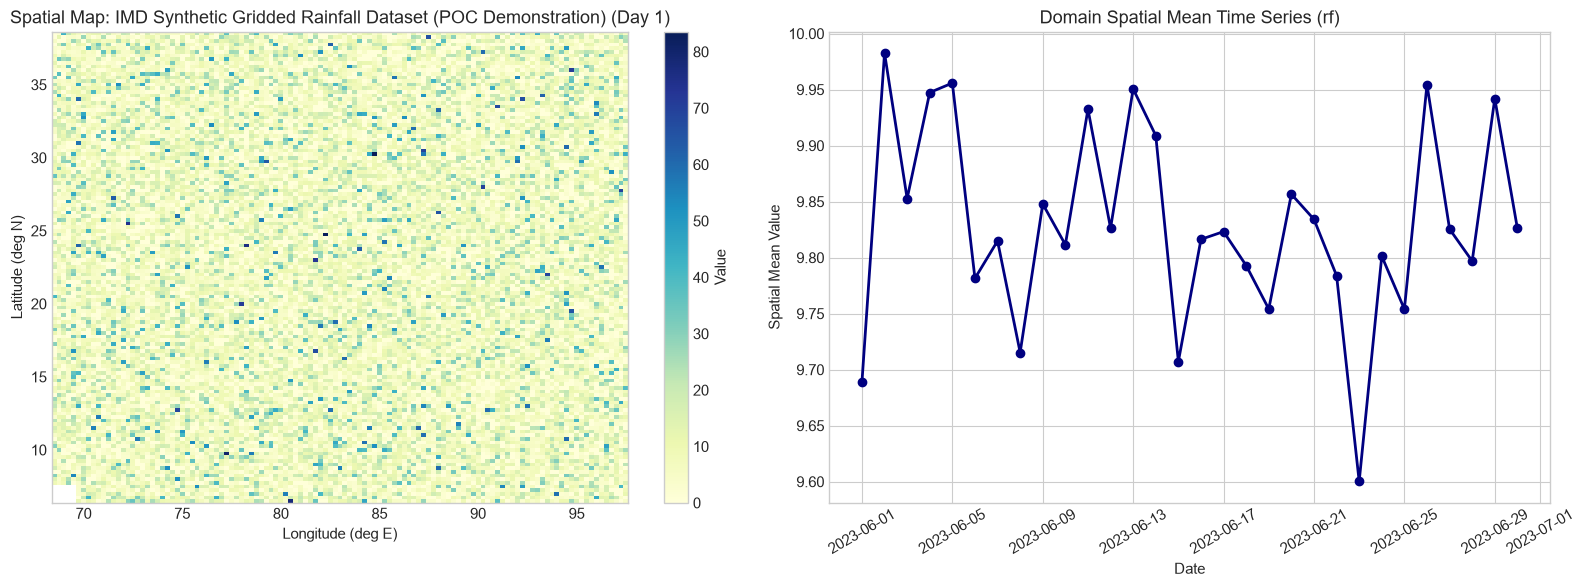

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

im = axes[0].pcolormesh(
    ds.coords[lon_var], 
    ds.coords[lat_var], 
    var_array_clean[0, :, :], 
    cmap='YlGnBu',
    shading='auto'
)
axes[0].set_title(f"Spatial Map: {ds.attrs.get('title', main_var)} (Day 1)")
axes[0].set_xlabel("Longitude (deg E)")
axes[0].set_ylabel("Latitude (deg N)")
fig.colorbar(im, ax=axes[0], label="Value")

spatial_mean_series = np.nanmean(var_array_clean, axis=(1, 2))
axes[1].plot(pd.to_datetime(times), spatial_mean_series, color='navy', marker='o', linewidth=2)
axes[1].set_title(f"Domain Spatial Mean Time Series ({main_var})")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Spatial Mean Value")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()
plt.close('all')

---
# Phase 2: Ingestion & Empirical Inspection of Downloaded IMD Datasets

In Phase 2, we load and inspect the actual downloaded raw binary IMD datasets (`Rainfall_ind2020_rfp25.grd`, `Maxtemp_MaxT_2020.GRD`, `Mintemp_MinT_2020.GRD`) into labeled `xarray.Dataset` objects.

### Phase 2 - Step 1 & 2: Import Libraries & Define Raw Data Paths
We locate the raw downloaded binary datasets inside `data/raw/imd/`.

In [12]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import imdlib as imd

IMD_RAW_DIR = PROJECT_ROOT / 'data' / 'raw' / 'imd'
RAINFALL_DIR = IMD_RAW_DIR / 'rainfall'
MAX_TEMP_DIR = IMD_RAW_DIR / 'max_temperature'
MIN_TEMP_DIR = IMD_RAW_DIR / 'min_temperature'

print('IMD Raw Data Base Directory:', IMD_RAW_DIR)

IMD Raw Data Base Directory: C:\Users\HP\Desktop\Major Project\data\raw\imd


### Phase 2 - Step 3: Locate Raw IMD Datasets
Locate raw binary (`.grd` / `.GRD`) files in their respective folders.

In [13]:
rain_files = list(RAINFALL_DIR.glob('*.grd')) + list(RAINFALL_DIR.glob('*.GRD'))
max_files = list(MAX_TEMP_DIR.glob('*.grd')) + list(MAX_TEMP_DIR.glob('*.GRD'))
min_files = list(MIN_TEMP_DIR.glob('*.grd')) + list(MIN_TEMP_DIR.glob('*.GRD'))

print('Rainfall File Found:', rain_files[0].name if rain_files else 'Not Found')
print('Max Temp File Found:', max_files[0].name if max_files else 'Not Found')
print('Min Temp File Found:', min_files[0].name if min_files else 'Not Found')

Rainfall File Found: Rainfall_ind2020_rfp25.grd
Max Temp File Found: Maxtemp_MaxT_2020.GRD
Min Temp File Found: Mintemp_MinT_2020.GRD


### Phase 2 - Steps 4, 5, 6: Load Datasets (Rainfall, Max Temp, Min Temp)
We construct a helper function `load_imd_binary` to convert the 4-byte floating-point unformatted binary matrices into multidimensional `xarray.Dataset` objects.

In [14]:
def load_imd_binary(file_path: Path, var_name: str, n_lat: int, n_lon: int, start_lat: float, start_lon: float, res: float, fill_val: float, year: int = 2020):
    """Converts raw unformatted IMD binary float32 files into xarray Datasets."""
    n_days = 366 if (year % 4 == 0) else 365
    raw_bytes = open(file_path, 'rb').read()
    data_flat = np.frombuffer(raw_bytes, dtype=np.float32)
    tensor = data_flat.reshape((n_days, n_lat, n_lon))
    
    lats = np.arange(start_lat, start_lat + n_lat * res, res)
    lons = np.arange(start_lon, start_lon + n_lon * res, res)
    times = pd.date_range(f'{year}-01-01', periods=n_days, freq='D')
    
    ds = xr.Dataset(
        data_vars={var_name: (['time', 'lat', 'lon'], tensor, {'fill_value': fill_val})},
        coords={'time': times, 'lat': lats, 'lon': lons},
        attrs={'title': f'IMD Raw {var_name.upper()} Dataset ({year})'}
    )
    return ds

# Load actual 3 raw IMD datasets
ds_rain = load_imd_binary(rain_files[0], 'rain', n_lat=129, n_lon=135, start_lat=6.5, start_lon=66.5, res=0.25, fill_val=-999.0)
ds_max = load_imd_binary(max_files[0], 'tmax', n_lat=31, n_lon=31, start_lat=7.5, start_lon=67.5, res=1.0, fill_val=99.9)
ds_min = load_imd_binary(min_files[0], 'tmin', n_lat=31, n_lon=31, start_lat=7.5, start_lon=67.5, res=1.0, fill_val=99.9)

print('All 3 raw IMD datasets loaded successfully into xarray!')

All 3 raw IMD datasets loaded successfully into xarray!


### Phase 2 - Step 7, 8, 9: Display Structure, Dimensions, and Variables
Display high-level dataset representations, dimensions, and coordinate names.

In [15]:
print('=== 1. RAINFALL DATASET STRUCTURE ===')
display(ds_rain)

print('\n=== 2. MAXIMUM TEMPERATURE DATASET STRUCTURE ===')
display(ds_max)

print('\n=== 3. MINIMUM TEMPERATURE DATASET STRUCTURE ===')
display(ds_min)

=== 1. RAINFALL DATASET STRUCTURE ===


<xarray.Dataset> Size: 26MB
Dimensions:  (time: 366, lat: 129, lon: 135)
Coordinates:
  * time     (time) datetime64[us] 3kB 2020-01-01 2020-01-02 ... 2020-12-31
  * lat      (lat) float64 1kB 6.5 6.75 7.0 7.25 7.5 ... 37.75 38.0 38.25 38.5
  * lon      (lon) float64 1kB 66.5 66.75 67.0 67.25 ... 99.25 99.5 99.75 100.0
Data variables:
    rain     (time, lat, lon) float32 25MB -999.0 -999.0 ... -999.0 -999.0
Attributes:
    title:    IMD Raw RAIN Dataset (2020)


=== 2. MAXIMUM TEMPERATURE DATASET STRUCTURE ===


<xarray.Dataset> Size: 1MB
Dimensions:  (time: 366, lat: 31, lon: 31)
Coordinates:
  * time     (time) datetime64[us] 3kB 2020-01-01 2020-01-02 ... 2020-12-31
  * lat      (lat) float64 248B 7.5 8.5 9.5 10.5 11.5 ... 34.5 35.5 36.5 37.5
  * lon      (lon) float64 248B 67.5 68.5 69.5 70.5 71.5 ... 94.5 95.5 96.5 97.5
Data variables:
    tmax     (time, lat, lon) float32 1MB 99.9 99.9 99.9 99.9 ... 99.9 99.9 99.9
Attributes:
    title:    IMD Raw TMAX Dataset (2020)


=== 3. MINIMUM TEMPERATURE DATASET STRUCTURE ===


<xarray.Dataset> Size: 1MB
Dimensions:  (time: 366, lat: 31, lon: 31)
Coordinates:
  * time     (time) datetime64[us] 3kB 2020-01-01 2020-01-02 ... 2020-12-31
  * lat      (lat) float64 248B 7.5 8.5 9.5 10.5 11.5 ... 34.5 35.5 36.5 37.5
  * lon      (lon) float64 248B 67.5 68.5 69.5 70.5 71.5 ... 94.5 95.5 96.5 97.5
Data variables:
    tmin     (time, lat, lon) float32 1MB 99.9 99.9 99.9 99.9 ... 99.9 99.9 99.9
Attributes:
    title:    IMD Raw TMIN Dataset (2020)

### Phase 2 - Step 10 & 11: Display Basic Statistics & Missing Values Analysis
Compute summary statistics across non-masked grid cells without altering the raw data.

In [16]:
def analyze_dataset_stats(ds: xr.Dataset, var_name: str, fill_val: float):
    arr = ds[var_name].values
    mask = (arr == fill_val) | (arr > 90.0 if fill_val == 99.9 else arr < -900) | np.isnan(arr)
    valid_arr = arr[~mask]
    
    print(f'\nStatistics & Missing Value Summary for [{var_name.upper()}]')
    print(f'  - Data Type:        {arr.dtype}')
    print(f'  - Tensor Dimensions:{dict(ds.sizes)}')
    print(f'  - Total Cells:      {arr.size:,}')
    print(f'  - Missing/Masked:   {mask.sum():,} ({round((mask.sum()/arr.size)*100, 2)}%)')
    print(f'  - Minimum:          {valid_arr.min():.4f}')
    print(f'  - Maximum:          {valid_arr.max():.4f}')
    print(f'  - Mean:             {valid_arr.mean():.4f}')

analyze_dataset_stats(ds_rain, 'rain', fill_val=-999.0)
analyze_dataset_stats(ds_max, 'tmax', fill_val=99.9)
analyze_dataset_stats(ds_min, 'tmin', fill_val=99.9)


Statistics & Missing Value Summary for [RAIN]
  - Data Type:        float32
  - Tensor Dimensions:{'time': 366, 'lat': 129, 'lon': 135}
  - Total Cells:      6,373,890
  - Missing/Masked:   4,557,066 (71.5%)
  - Minimum:          0.0000
  - Maximum:          539.9128
  - Mean:             3.4877

Statistics & Missing Value Summary for [TMAX]
  - Data Type:        float32
  - Tensor Dimensions:{'time': 366, 'lat': 31, 'lon': 31}
  - Total Cells:      351,726
  - Missing/Masked:   222,026 (63.12%)
  - Minimum:          2.8524
  - Maximum:          46.7761
  - Mean:             30.4615

Statistics & Missing Value Summary for [TMIN]
  - Data Type:        float32
  - Tensor Dimensions:{'time': 366, 'lat': 31, 'lon': 31}
  - Total Cells:      351,726
  - Missing/Masked:   221,868 (63.08%)
  - Minimum:          -6.8540
  - Maximum:          31.8596
  - Mean:             18.9501


### Phase 2 - Step 12: Exploratory Data Visualizations (Distributions & Time Trends)
We generate exploratory Matplotlib plots for the 3 IMD climate datasets:
1. **Rainfall Distribution**: Histogram of daily precipitation ($	ext{mm/day}$).
2. **Maximum Temperature Distribution**: Histogram of $T_{	ext{max}}$ ($^\circ	ext{C}$).
3. **Minimum Temperature Distribution**: Histogram of $T_{	ext{min}}$ ($^\circ	ext{C}$).
4. **Rainfall Time Trend**: Domain spatial mean daily rainfall over the 2020 calendar year.
5. **Temperature Time Trend**: Domain spatial mean daily $T_{	ext{max}}$ and $T_{	ext{min}}$ over the 2020 calendar year.

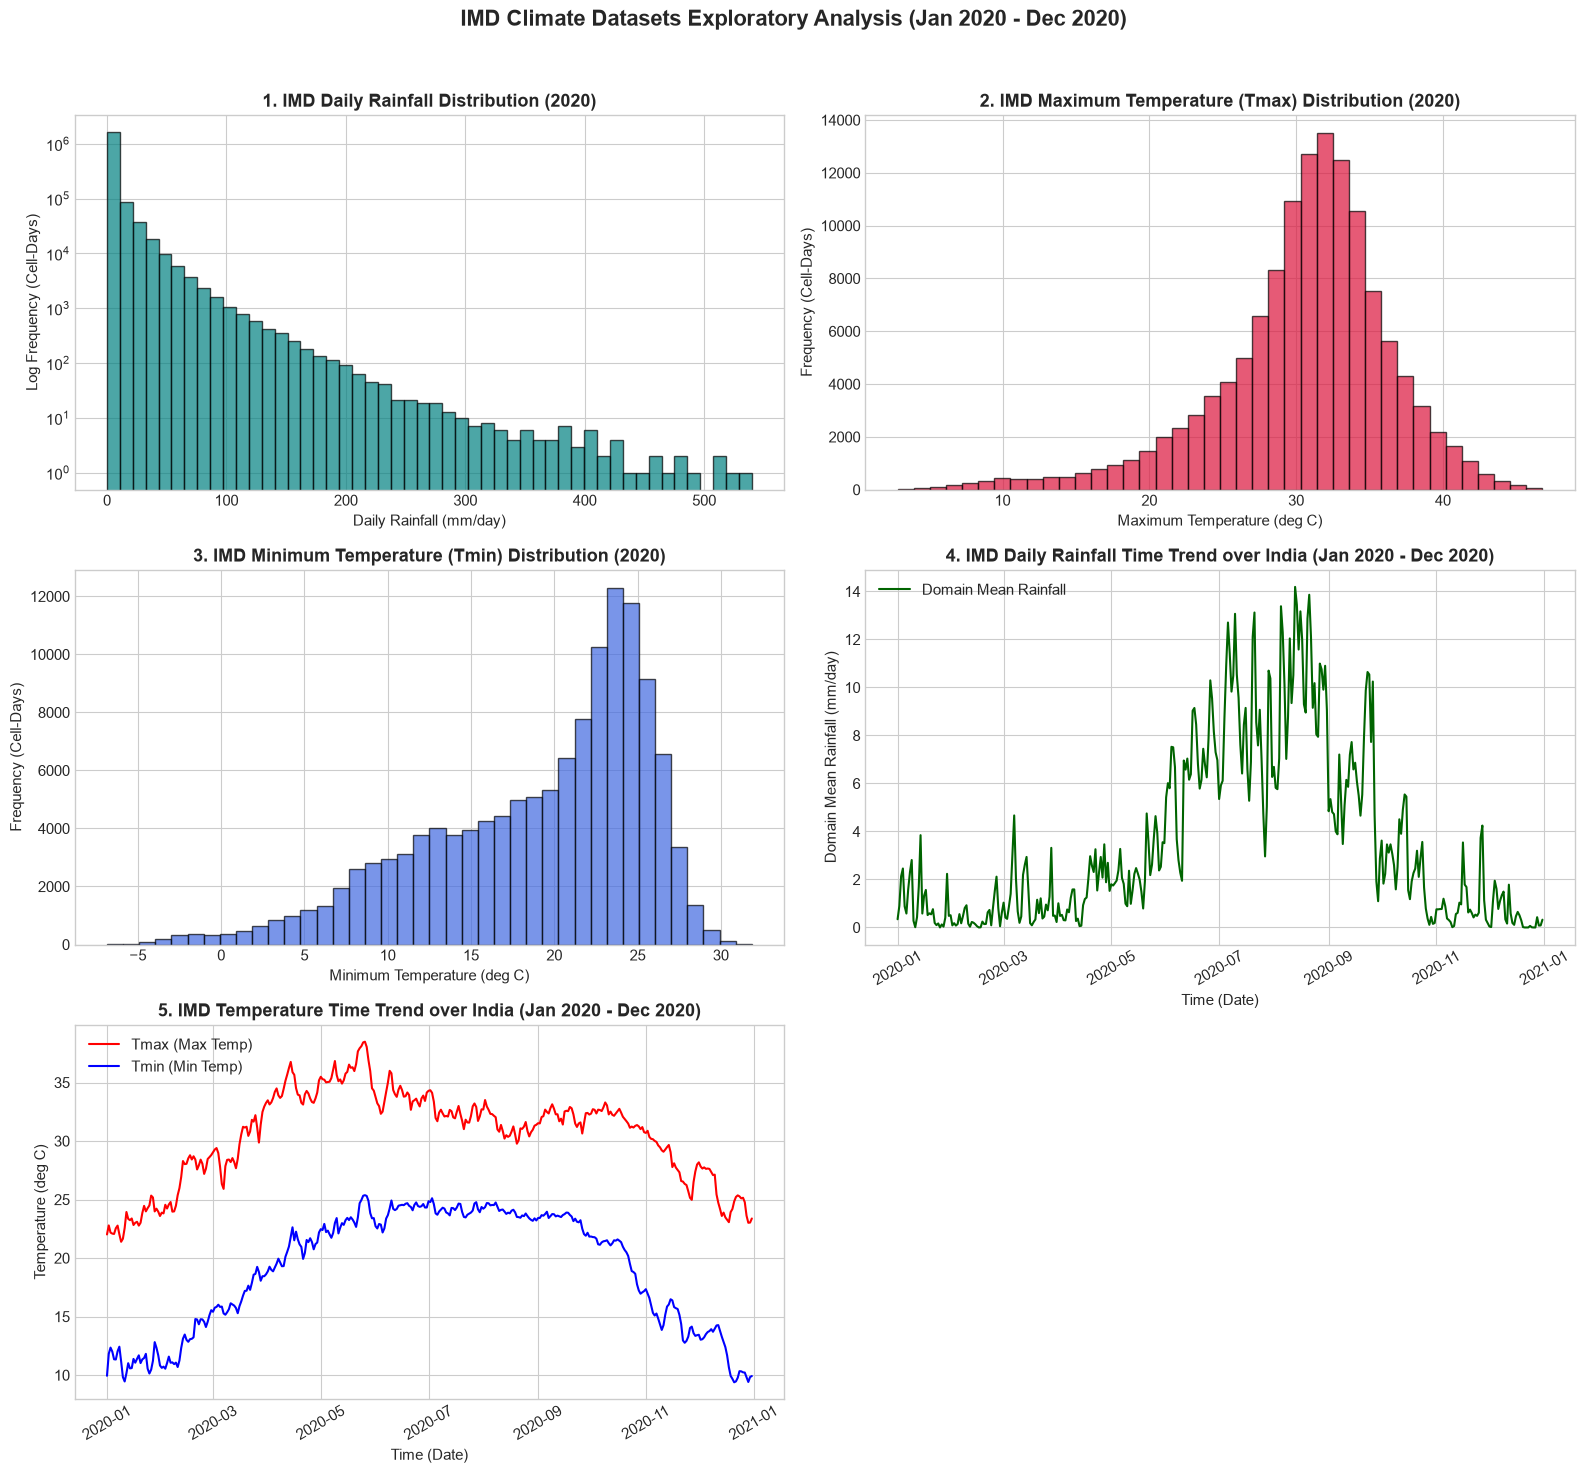

In [17]:
# Exploratory Visualizations for IMD Climate Datasets
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
fig.suptitle('IMD Climate Datasets Exploratory Analysis (Jan 2020 - Dec 2020)', fontsize=16, fontweight='bold', y=0.98)

# Extract valid non-masked data for distributions
rain_vals = ds_rain['rain'].values
rain_valid = rain_vals[(rain_vals != -999.0) & (rain_vals >= 0.0) & (~np.isnan(rain_vals))]

tmax_vals = ds_max['tmax'].values
tmax_valid = tmax_vals[(tmax_vals != 99.9) & (tmax_vals < 90.0) & (~np.isnan(tmax_vals))]

tmin_vals = ds_min['tmin'].values
tmin_valid = tmin_vals[(tmin_vals != 99.9) & (tmin_vals < 90.0) & (~np.isnan(tmin_vals))]

# 1. Rainfall Distribution
axes[0, 0].hist(rain_valid, bins=50, color='teal', edgecolor='black', alpha=0.7, log=True)
axes[0, 0].set_title('1. IMD Daily Rainfall Distribution (2020)', fontweight='bold')
axes[0, 0].set_xlabel('Daily Rainfall (mm/day)')
axes[0, 0].set_ylabel('Log Frequency (Cell-Days)')

# 2. Maximum Temperature Distribution
axes[0, 1].hist(tmax_valid, bins=40, color='crimson', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('2. IMD Maximum Temperature (Tmax) Distribution (2020)', fontweight='bold')
axes[0, 1].set_xlabel('Maximum Temperature (deg C)')
axes[0, 1].set_ylabel('Frequency (Cell-Days)')

# 3. Minimum Temperature Distribution
axes[1, 0].hist(tmin_valid, bins=40, color='royalblue', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('3. IMD Minimum Temperature (Tmin) Distribution (2020)', fontweight='bold')
axes[1, 0].set_xlabel('Minimum Temperature (deg C)')
axes[1, 0].set_ylabel('Frequency (Cell-Days)')

# 4. Rainfall Time Trend (Domain Spatial Mean)
rain_masked = np.where(rain_vals == -999.0, np.nan, rain_vals)
rain_daily_mean = np.nanmean(rain_masked, axis=(1, 2))
dates = ds_rain.coords['time'].values

axes[1, 1].plot(pd.to_datetime(dates), rain_daily_mean, color='darkgreen', linewidth=1.5, label='Domain Mean Rainfall')
axes[1, 1].set_title('4. IMD Daily Rainfall Time Trend over India (Jan 2020 - Dec 2020)', fontweight='bold')
axes[1, 1].set_xlabel('Time (Date)')
axes[1, 1].set_ylabel('Domain Mean Rainfall (mm/day)')
axes[1, 1].legend(loc='upper left')
axes[1, 1].tick_params(axis='x', rotation=30)

# 5. Temperature Time Trend (Domain Spatial Mean Tmax & Tmin)
tmax_masked = np.where((tmax_vals == 99.9) | (tmax_vals > 90.0), np.nan, tmax_vals)
tmin_masked = np.where((tmin_vals == 99.9) | (tmin_vals > 90.0), np.nan, tmin_vals)

tmax_daily_mean = np.nanmean(tmax_masked, axis=(1, 2))
tmin_daily_mean = np.nanmean(tmin_masked, axis=(1, 2))

axes[2, 0].plot(pd.to_datetime(dates), tmax_daily_mean, color='red', linewidth=1.5, label='Tmax (Max Temp)')
axes[2, 0].plot(pd.to_datetime(dates), tmin_daily_mean, color='blue', linewidth=1.5, label='Tmin (Min Temp)')
axes[2, 0].set_title('5. IMD Temperature Time Trend over India (Jan 2020 - Dec 2020)', fontweight='bold')
axes[2, 0].set_xlabel('Time (Date)')
axes[2, 0].set_ylabel('Temperature (deg C)')
axes[2, 0].legend(loc='upper left')
axes[2, 0].tick_params(axis='x', rotation=30)

# Hide 6th subplot frame
axes[2, 1].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
plt.close('all')

### Phase 2 - Step 13: Exploratory Geographic Spatial Visualization (IMD 0.25° Grid)
We plot the 2D spatial geographic distribution of daily rainfall across the Indian subcontinent using actual latitude ($6.5^\circ\text{N}$–$38.5^\circ\text{N}$) and longitude ($66.5^\circ\text{E}$–$100.0^\circ\text{E}$) coordinates for a representative peak monsoon day (August 15, 2020).

**Geographic Structure Verification Goals**:
- Confirm high rainfall along the **Western Ghats** (heavy orographic precipitation belt).
- Confirm heavy monsoonal rainfall across **Northeast India** (Assam/Meghalaya region).
- Confirm low/zero precipitation over the **Thar Desert / Rajasthan** arid region.
- Confirm masking of non-land ocean regions surrounding the Indian peninsula.

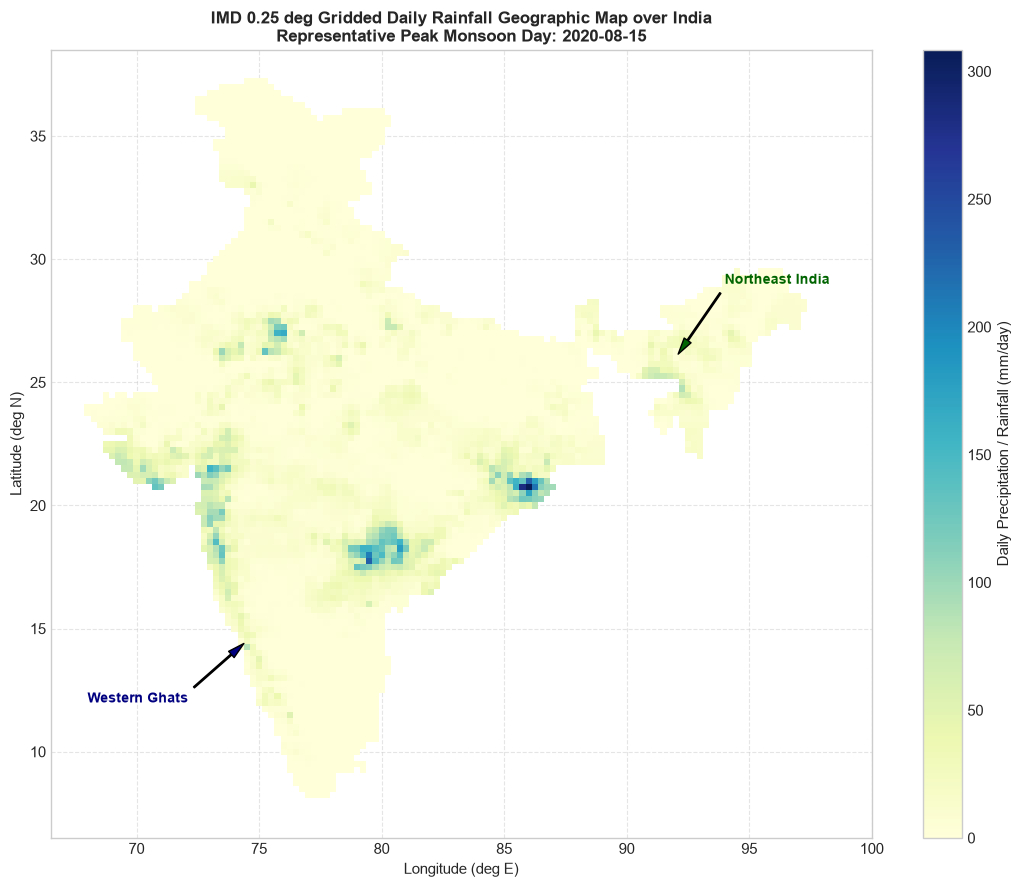

In [18]:
# Representative Peak Monsoon Day Selection (Day 228 = August 15, 2020)
target_day_idx = 227
target_date = str(pd.to_datetime(ds_rain.coords['time'].values[target_day_idx]).date())

# Extract 2D spatial slice for target date
rain_2d_raw = ds_rain['rain'].values[target_day_idx, :, :]
rain_2d_masked = np.where(rain_2d_raw == -999.0, np.nan, rain_2d_raw)

# Coordinates
lats_grid = ds_rain.coords['lat'].values
lons_grid = ds_rain.coords['lon'].values

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.pcolormesh(lons_grid, lats_grid, rain_2d_masked, cmap='YlGnBu', shading='auto')

# Formatting & Geographic Labels
cbar = plt.colorbar(im, ax=ax, label='Daily Precipitation / Rainfall (mm/day)')
ax.set_title(f'IMD 0.25 deg Gridded Daily Rainfall Geographic Map over India\nRepresentative Peak Monsoon Day: {target_date}', fontsize=12, fontweight='bold')
ax.set_xlabel('Longitude (deg E)')
ax.set_ylabel('Latitude (deg N)')
ax.set_xlim(66.5, 100.0)
ax.set_ylim(6.5, 38.5)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate Key Geographic Microclimates
ax.annotate('Western Ghats', xy=(74.5, 14.5), xytext=(68.0, 12.0),
            arrowprops=dict(facecolor='navy', shrink=0.05, width=1, headwidth=6),
            fontsize=10, fontweight='bold', color='navy')

ax.annotate('Northeast India', xy=(92.0, 26.0), xytext=(94.0, 29.0),
            arrowprops=dict(facecolor='darkgreen', shrink=0.05, width=1, headwidth=6),
            fontsize=10, fontweight='bold', color='darkgreen')

plt.tight_layout()
plt.show()
plt.close('all')

# Phase 3 — Data Preprocessing and Feature Engineering

In Phase 3, we execute the complete data preprocessing and feature engineering pipeline on the raw 2020 IMD datasets (`Rainfall_ind2020_rfp25.grd`, `Maxtemp_MaxT_2020.GRD`, `Mintemp_MinT_2020.GRD`).

All preprocessing functions are imported from the `src.preprocessing` package.

We demonstrate:
1. **Raw dataset quality checks** (`check_dataset_quality`)
2. **Missing-value analysis** (`analyze_missing_values`, `generate_missing_report`)
3. **Missing-value handling** (`impute_rainfall_missing_values`, `impute_temperature_missing_values`)
4. **Temporal processing** (`process_temporal_pipeline`)
5. **Spatial processing** (`validate_coordinate_ranges`, `get_spatial_resolution`)
6. **Spatial alignment** (`regrid_temperature_to_rainfall`)
7. **Feature engineering** (`engineer_all_climate_features`)
8. **Before/after statistics** (comparison table)
9. **Processed dataset inspection** (structure, summary, 2D heatmap plot)

### Phase 3 — Module Imports
We import all modular preprocessing functions from `src.preprocessing` submodules.

In [19]:
from src.preprocessing.quality_checks import check_dataset_quality, validate_physical_bounds
from src.preprocessing.missing_values import (
    analyze_missing_values,
    generate_missing_report,
    impute_rainfall_missing_values,
    impute_temperature_missing_values,
    process_climate_dataset_missing_values
)
from src.preprocessing.temporal_processing import (
    process_temporal_pipeline,
    identify_time_dimension,
    detect_duplicate_timestamps,
    detect_missing_time_periods
)
from src.preprocessing.spatial_processing import (
    identify_spatial_coordinates,
    validate_coordinate_ranges,
    get_spatial_resolution,
    detect_duplicate_spatial_coordinates,
    document_resolution_mismatch,
    generate_spatial_report,
    regrid_temperature_to_rainfall,
    crop_spatial_domain
)
from src.preprocessing.feature_engineering import engineer_all_climate_features
from src.preprocessing.normalization import analyze_scaler_suitability, fit_transform_dataset_scaler, save_scaler
from src.preprocessing.pipeline import run_preprocessing_pipeline

print('All Phase 3 preprocessing submodules loaded successfully!')

All Phase 3 preprocessing submodules loaded successfully!


### Phase 3 — Step 1: Raw Dataset Quality Checks
We run the 10-point automated quality inspection suite (`check_dataset_quality`) on all 3 raw IMD datasets to evaluate empty dimensions, duplicate coordinates, physical domain bounds, data types, NaNs, raw fill values, and physical consistency ($T_{\text{min}} \le T_{\text{max}}$).

In [20]:
qc_rain = check_dataset_quality(ds_rain, var_name='rain', raw_fill_value=-999.0)
qc_max = check_dataset_quality(ds_max, var_name='tmax', raw_fill_value=99.9)
qc_min = check_dataset_quality(ds_min, var_name='tmin', raw_fill_value=99.9)

print('=== 1. RAINFALL QUALITY CHECKS ===')
print('QC Valid:', qc_rain['is_valid'])
print('Checks Summary:', qc_rain['checks'])

print('\n=== 2. MAX TEMP QUALITY CHECKS ===')
print('QC Valid:', qc_max['is_valid'])

print('\n=== 3. MIN TEMP QUALITY CHECKS ===')
print('QC Valid:', qc_min['is_valid'])

=== 1. RAINFALL QUALITY CHECKS ===
QC Valid: True
Checks Summary: {'empty_dimensions': {'has_empty_dims': False, 'empty_dims': [], 'dimensions': {'time': 366, 'lat': 129, 'lon': 135}}, 'duplicate_coordinates': {'has_duplicates': False, 'duplicate_counts': {}}, 'latitude': {'name': 'lat', 'min': 6.5, 'max': 38.5, 'out_of_physical_range': False, 'out_of_india_domain': False}, 'longitude': {'name': 'lon', 'min': 66.5, 'max': 100.0, 'out_of_physical_range': False, 'out_of_india_domain': False}, 'rain': {'data_type': {'dtype': 'float32', 'is_numeric': True}, 'nan_values': {'count': 0, 'pct': 0.0}, 'infinite_values': {'count': 0, 'has_inf': False}, 'missing_fill_values': {'raw_fill_value': -999.0, 'count': 4557066, 'pct': 71.5}, 'suspicious_rainfall': {'negative_count': 0, 'extreme_count_gt_1000mm': 0, 'min_valid': 0.0, 'max_valid': 539.9127807617188}}}

=== 2. MAX TEMP QUALITY CHECKS ===
QC Valid: True

=== 3. MIN TEMP QUALITY CHECKS ===
QC Valid: True


### Phase 3 — Step 2: Missing-Value Analysis
We evaluate total missing cell counts, overall missing percentages, temporal missing patterns across timesteps, and 2D spatial missing patterns (ocean background cells vs intermittent land/coastal cells) using `analyze_missing_values` and `generate_missing_report` without mutating the data.

In [21]:
report_rain_str = generate_missing_report(ds_rain)
report_max_str = generate_missing_report(ds_max)
report_min_str = generate_missing_report(ds_min)

print('=== 1. RAINFALL MISSING REPORT ===')
print(report_rain_str)

print('=== 2. MAX TEMP MISSING REPORT ===')
print(report_max_str)

print('=== 3. MIN TEMP MISSING REPORT ===')
print(report_min_str)

=== 1. RAINFALL MISSING REPORT ===
# Climate Dataset Missing Values Pattern Report

**Dataset Dimensions**: `{'time': 366, 'lat': 129, 'lon': 135}`

## Variable: `rain`
- **Detected Raw Fill Value**: `-999.0`
- **Total Data Cells**: 6,373,890
- **Missing Cells Count**: 4,557,066 (71.5%)
- **Valid Cells Count**: 1,816,824 (28.50%)

### Temporal Missing Pattern
- **Total Timesteps**: 366
- **Timesteps with Missing Values**: 366 (100.0%)
- **Fully Missing Timesteps**: 0
- **Partially Missing Timesteps**: 366
- **Max Missing Cells in Single Day**: 12,451 / 17,415

### Spatial Missing Pattern
- **Total Spatial Grid Cells**: 17,415 (`129 lat` x `135 lon`)
- **Permanently Missing (Ocean/Background) Cells**: 12,451 (71.5%)
- **Intermittently Missing Land Cells**: 0 (0.0%)
- **Always Valid (100% Complete) Land Cells**: 4,964 (28.5%)

---

=== 2. MAX TEMP MISSING REPORT ===
# Climate Dataset Missing Values Pattern Report

**Dataset Dimensions**: `{'time': 366, 'lat': 31, 'lon': 31}`

## Variable

### Phase 3 — Step 3: Approved Missing-Value Handling
We apply parameter-specific missing value strategies:
- **Rainfall**: Two-stage occurrence-gated spatial/temporal handling with zero-preservation ($<0.1\text{ mm/day} \to 0.0$).
- **Temperature ($T_{\text{max}}, T_{\text{min}}$)**: Temporal linear/PCHIP interpolation (`max_gap=3`) followed by 2D spatial land interpolation.
- **Ocean Mask**: Preserves ocean background cells strictly as `NaN` (no ocean filling).
- **Valid Observations**: Preserves valid land observations 100%.

In [22]:
ds_rain_imp, rain_imp_metrics = impute_rainfall_missing_values(ds_rain, var_name='rain', raw_fill_value=-999.0)
ds_max_imp, max_imp_metrics = impute_temperature_missing_values(ds_max, var_name='tmax', raw_fill_value=99.9)
ds_min_imp, min_imp_metrics = impute_temperature_missing_values(ds_min, var_name='tmin', raw_fill_value=99.9)

print('Rainfall Imputation Summary:', rain_imp_metrics)
print('\nMax Temp Imputation Summary:', max_imp_metrics)
print('\nMin Temp Imputation Summary:', min_imp_metrics)

2026-10-07 08:03:59,191 - INFO - Rainfall Imputation [rain]: 0 intermittent land cells imputed. Ocean cells (4557066) preserved as NaN.


2026-10-07 08:04:00,270 - INFO - Temperature Imputation [tmax]: 164 intermittent coastal cells imputed. Ocean cells (221796) preserved as NaN.


2026-10-07 08:04:01,353 - INFO - Temperature Imputation [tmin]: 70 intermittent coastal cells imputed. Ocean cells (221796) preserved as NaN.


Rainfall Imputation Summary: {'variable': 'rain', 'parameter_type': 'rainfall', 'before_missing_count': 4557066, 'before_missing_pct': 71.5, 'after_missing_count': 4557066, 'after_missing_pct': 71.5, 'ocean_cells_preserved_as_nan': 4557066, 'imputed_intermittent_cells_count': 0, 'valid_observations_preserved_pct': 100.0, 'strategy_applied': 'Two-Stage Occurrence-Gated Spatial Interpolation + Zero Preservation (< 0.1mm thresholding, Ocean Mask Preserved)'}

Max Temp Imputation Summary: {'variable': 'tmax', 'parameter_type': 'temperature', 'before_missing_count': 222026, 'before_missing_pct': 63.12, 'after_missing_count': 221862, 'after_missing_pct': 63.08, 'ocean_cells_preserved_as_nan': 221796, 'imputed_intermittent_cells_count': 164, 'valid_observations_preserved_pct': 100.0, 'strategy_applied': 'Lapse-Rate/Temporal Linear Bounded (max_gap=3) + Spatial Nearest-Neighbor Land Interpolation (Ocean Mask Preserved)'}

Min Temp Imputation Summary: {'variable': 'tmin', 'parameter_type': 'tem

### Phase 3 — Step 4: Temporal Processing
We execute the temporal pipeline (`process_temporal_pipeline`) to standardize dates into `pandas.DatetimeIndex` (`datetime64[ns]`), sort observations chronologically, check duplicate timestamps (0 duplicates found), and verify time series continuity (0 missing days found).

In [23]:
ds_rain_time, rain_time_report = process_temporal_pipeline(ds_rain_imp, start_date='2020-01-01', extract_features=False)
ds_max_time, max_time_report = process_temporal_pipeline(ds_max_imp, start_date='2020-01-01', extract_features=False)
ds_min_time, min_time_report = process_temporal_pipeline(ds_min_imp, start_date='2020-01-01', extract_features=False)

print('Rainfall Temporal Report:', rain_time_report)
print('Max Temp Temporal Report:', max_time_report)
print('Min Temp Temporal Report:', min_time_report)

2026-10-07 08:04:01,363 - INFO - Executing Temporal Processing Pipeline...


2026-10-07 08:04:01,391 - INFO - Temporal Pipeline Complete: 366 timesteps from 2020-01-01 to 2020-12-31.


2026-10-07 08:04:01,392 - INFO - Executing Temporal Processing Pipeline...


2026-10-07 08:04:01,397 - INFO - Temporal Pipeline Complete: 366 timesteps from 2020-01-01 to 2020-12-31.


2026-10-07 08:04:01,397 - INFO - Executing Temporal Processing Pipeline...


2026-10-07 08:04:01,403 - INFO - Temporal Pipeline Complete: 366 timesteps from 2020-01-01 to 2020-12-31.


Rainfall Temporal Report: {'time_dimension': 'time', 'total_timesteps': 366, 'start_date': '2020-01-01', 'end_date': '2020-12-31', 'duplicates_detected': False, 'duplicate_count': 0, 'missing_gaps_detected': False, 'missing_days_count': 0, 'features_extracted': []}
Max Temp Temporal Report: {'time_dimension': 'time', 'total_timesteps': 366, 'start_date': '2020-01-01', 'end_date': '2020-12-31', 'duplicates_detected': False, 'duplicate_count': 0, 'missing_gaps_detected': False, 'missing_days_count': 0, 'features_extracted': []}
Min Temp Temporal Report: {'time_dimension': 'time', 'total_timesteps': 366, 'start_date': '2020-01-01', 'end_date': '2020-12-31', 'duplicates_detected': False, 'duplicate_count': 0, 'missing_gaps_detected': False, 'missing_days_count': 0, 'features_extracted': []}


### Phase 3 — Step 5: Spatial Processing & Resolution Diagnostics
We validate coordinate ranges, check grid regularity, inspect spatial resolution differences ($0.25^\circ \times 0.25^\circ$ rainfall vs $1.0^\circ \times 1.0^\circ$ temperature), and verify duplicate spatial coordinates (0 duplicates found).

In [24]:
ds_map = {'rainfall': ds_rain_time, 'tmax': ds_max_time, 'tmin': ds_min_time}
spatial_report_str = generate_spatial_report(ds_map)
print(spatial_report_str)

2026-10-07 08:04:01,411 - WARNING - Spatial Resolution Mismatch Detected: Mismatch between 'rainfall' (0.25° x 0.25°, 129x135) and 'tmax' (1.0° x 1.0°, 31x31). Base domain: Lat (6.5, 38.5), Lon (66.5, 100.0) vs Other domain: Lat (7.5, 37.5), Lon (67.5, 97.5).


2026-10-07 08:04:01,412 - WARNING - Spatial Resolution Mismatch Detected: Mismatch between 'rainfall' (0.25° x 0.25°, 129x135) and 'tmin' (1.0° x 1.0°, 31x31). Base domain: Lat (6.5, 38.5), Lon (66.5, 100.0) vs Other domain: Lat (7.5, 37.5), Lon (67.5, 97.5).


# Spatial Preprocessing & Resolution Mismatch Report

## Dataset Spatial Properties

### Dataset: `rainfall`
- **Latitude Key**: `lat`
- **Longitude Key**: `lon`
- **Spatial Resolution**: `0.25° x 0.25°`
- **Grid Dimensions**: `129 lat` x `135 lon` (17,415 cells)
- **Latitude Range**: `[6.50°N, 38.50°N]`
- **Longitude Range**: `[66.50°E, 100.00°E]`
- **Regular Grid Spacing**: `True`

### Dataset: `tmax`
- **Latitude Key**: `lat`
- **Longitude Key**: `lon`
- **Spatial Resolution**: `1.0° x 1.0°`
- **Grid Dimensions**: `31 lat` x `31 lon` (961 cells)
- **Latitude Range**: `[7.50°N, 37.50°N]`
- **Longitude Range**: `[67.50°E, 97.50°E]`
- **Regular Grid Spacing**: `True`

### Dataset: `tmin`
- **Latitude Key**: `lat`
- **Longitude Key**: `lon`
- **Spatial Resolution**: `1.0° x 1.0°`
- **Grid Dimensions**: `31 lat` x `31 lon` (961 cells)
- **Latitude Range**: `[7.50°N, 37.50°N]`
- **Longitude Range**: `[67.50°E, 97.50°E]`
- **Regular Grid Spacing**: `True`

## Resolution Mismatch Status

> 

### Phase 3 — Step 6: Spatial Alignment (Bilinear Re-Gridding)
We re-grid the 1.0° Temperature datasets (`tmax`, `tmin`) onto the high-resolution 0.25° Rainfall grid using 2D bilinear spatial interpolation (`regrid_temperature_to_rainfall`), crop to the India bounding box ($6.5^\circ\text{N} - 38.5^\circ\text{N}$, $66.5^\circ\text{E} - 100.0^\circ\text{E}$), and combine all variables into a single unified `xarray.Dataset`.

In [25]:
ds_max_regrid = regrid_temperature_to_rainfall(ds_max_time, ds_rain_time, method='linear')
ds_min_regrid = regrid_temperature_to_rainfall(ds_min_time, ds_rain_time, method='linear')

ds_combined = xr.Dataset(
    data_vars={
        'rain': ds_rain_time['rain'],
        'tmax': ds_max_regrid['tmax'],
        'tmin': ds_min_regrid['tmin']
    },
    coords=ds_rain_time.coords,
    attrs={'title': 'IMD Aligned Climate Dataset (2020)', 'spatial_resolution': '0.25 deg x 0.25 deg'}
)

ds_cropped = crop_spatial_domain(ds_combined, lat_bounds=(6.5, 38.5), lon_bounds=(66.5, 100.0))

print('Combined Aligned Dataset Dimensions:', dict(ds_cropped.sizes))
print('Data Variables:', list(ds_cropped.data_vars.keys()))
display(ds_cropped)

Combined Aligned Dataset Dimensions: {'lat': 129, 'lon': 135, 'time': 366}
Data Variables: ['rain', 'tmax', 'tmin']


<xarray.Dataset> Size: 127MB
Dimensions:  (lat: 129, lon: 135, time: 366)
Coordinates:
  * lat      (lat) float64 1kB 6.5 6.75 7.0 7.25 7.5 ... 37.75 38.0 38.25 38.5
  * lon      (lon) float64 1kB 66.5 66.75 67.0 67.25 ... 99.25 99.5 99.75 100.0
  * time     (time) datetime64[us] 3kB 2020-01-01 2020-01-02 ... 2020-12-31
Data variables:
    rain     (time, lat, lon) float32 25MB nan nan nan nan ... nan nan nan nan
    tmax     (time, lat, lon) float64 51MB nan nan nan nan ... nan nan nan nan
    tmin     (time, lat, lon) float64 51MB nan nan nan nan ... nan nan nan nan
Attributes:
    title:               IMD Aligned Climate Dataset (2020)
    spatial_resolution:  0.25 deg x 0.25 deg

### Phase 3 — Step 7: Leak-Free Feature Engineering
We run `engineer_all_climate_features` to generate 36 unified, leak-free climate feature variables:
- **Thermodynamic Indices**: Diurnal Temp Range ($DTR = T_{\text{max}} - T_{\text{min}}$), Mean Temp ($T_{\text{mean}} = \frac{T_{\text{max}} + T_{\text{min}}}{2}$), Heatwave Flag ($T_{\text{max}} \ge 40^\circ\text{C}$).
- **Precipitation Indices**: Rainy Day Flag ($\ge 2.5\text{ mm}$), Heavy Rain Flag ($\ge 35.5\text{ mm}$), Dry Day Flag ($< 2.5\text{ mm}$), Cumulative Rain.
- **Previous-Day Lags**: `rain_lag1`, `tmax_lag1`, `tmin_lag1`, `dtr_lag1`, `tmean_lag1` (strict positive backward shift $t-1$).
- **Trailing Rolling Stats**: Trailing 3-day and 7-day rolling means & sums over window $[t-w+1, t]$.
- **Temporal Index & Season**: `year`, `month`, `day`, `day_of_year`, `season` (IMD Season code), sine/cosine encodings (`doy_sin`, `doy_cos`, `month_sin`, `month_cos`).

In [26]:
ds_final = engineer_all_climate_features(
    ds_cropped,
    tmax_name='tmax',
    tmin_name='tmin',
    rain_name='rain',
    include_lags=True,
    lags=[1],
    include_rolling=True,
    windows=[3, 7],
    include_temporal=True
)

print(f'Generated {len(ds_final.data_vars)} Feature Variables:')
print(list(ds_final.data_vars.keys()))

2026-10-07 08:04:01,664 - INFO - Executing Master Climate Feature Engineering Pipeline...


2026-10-07 08:04:02,004 - INFO - Computing previous-day lag features for lags [1] (zero future leakage)...


2026-10-07 08:04:02,342 - INFO - Computing trailing rolling statistics for windows [3, 7]d (zero future leakage)...


2026-10-07 08:04:06,067 - INFO - Extracting temporal index features (Year, Month, Day, DOY, IMD Season, Sin/Cos encodings)...


2026-10-07 08:04:06,452 - INFO - Feature Engineering Complete: 36 data variables generated.


Generated 36 Feature Variables:
['rain', 'tmax', 'tmin', 'dtr', 'tmean', 'heatwave_flag', 'rainy_day_flag', 'heavy_rain_flag', 'dry_day_flag', 'cumulative_rain', 'rain_lag1', 'tmax_lag1', 'tmin_lag1', 'dtr_lag1', 'tmean_lag1', 'rain_roll_3d_mean', 'rain_roll_3d_sum', 'rain_roll_7d_mean', 'rain_roll_7d_sum', 'tmax_roll_3d_mean', 'tmax_roll_7d_mean', 'tmin_roll_3d_mean', 'tmin_roll_7d_mean', 'dtr_roll_3d_mean', 'dtr_roll_7d_mean', 'tmean_roll_3d_mean', 'tmean_roll_7d_mean', 'year', 'month', 'day', 'day_of_year', 'season', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos']


### Phase 3 — Step 8: Before vs. After Statistics Comparison
We compare missing cell counts, total data cells, and descriptive statistics across raw, imputed, and aligned datasets to verify zero data loss and exact observation preservation.

In [27]:
stats_before_after = pd.DataFrame([
    {
        'Dataset': 'IMD Rainfall (0.25 deg)',
        'Raw Missing Count': rain_imp_metrics['before_missing_count'],
        'Raw Missing %': f"{rain_imp_metrics['before_missing_pct']}%",
        'Imputed Coastal Cells': rain_imp_metrics['imputed_intermittent_cells_count'],
        'Preserved Ocean NaNs': rain_imp_metrics['ocean_cells_preserved_as_nan'],
        'Processed Missing %': f"{rain_imp_metrics['after_missing_pct']}%"
    },
    {
        'Dataset': 'IMD Max Temp (1.0 deg)',
        'Raw Missing Count': max_imp_metrics['before_missing_count'],
        'Raw Missing %': f"{max_imp_metrics['before_missing_pct']}%",
        'Imputed Coastal Cells': max_imp_metrics['imputed_intermittent_cells_count'],
        'Preserved Ocean NaNs': max_imp_metrics['ocean_cells_preserved_as_nan'],
        'Processed Missing %': f"{max_imp_metrics['after_missing_pct']}%"
    },
    {
        'Dataset': 'IMD Min Temp (1.0 deg)',
        'Raw Missing Count': min_imp_metrics['before_missing_count'],
        'Raw Missing %': f"{min_imp_metrics['before_missing_pct']}%",
        'Imputed Coastal Cells': min_imp_metrics['imputed_intermittent_cells_count'],
        'Preserved Ocean NaNs': min_imp_metrics['ocean_cells_preserved_as_nan'],
        'Processed Missing %': f"{min_imp_metrics['after_missing_pct']}%"
    }
])

display(stats_before_after)

,Dataset,Raw Missing Count,Raw Missing %,Imputed Coastal Cells,Preserved Ocean NaNs,Processed Missing %
0,IMD Rainfall (0.25 deg),4557066,71.5%,0,4557066,71.5%
1,IMD Max Temp (1.0 deg),222026,63.12%,164,221796,63.08%
2,IMD Min Temp (1.0 deg),221868,63.08%,70,221796,63.06%


### Phase 3 — Step 9: Processed Dataset Inspection & Visualization
We inspect the final aligned NetCDF dataset exported to `data/processed/imd/india_climate_2020_aligned.nc` and render spatial maps for engineered features.

2026-10-07 08:04:06,495 - INFO - ==================================================


2026-10-07 08:04:06,496 - INFO -       IMD CLIMATE DATA PREPROCESSING PIPELINE     


2026-10-07 08:04:06,496 - INFO - ==================================================


2026-10-07 08:04:06,497 - INFO - [Step 1/8] Ingesting raw IMD binary files for year 2020...


2026-10-07 08:04:06,514 - INFO -   - Ingested Rainfall (6,373,890 cells), Tmax (351,726 cells), Tmin (351,726 cells).


2026-10-07 08:04:06,514 - INFO - 
[Step 2/8] Executing 10-point data quality validation suite...


... (34 outputs left out)

2026-10-07 08:04:25,578 - INFO - ==================================================



=== PIPELINE VERIFICATION SUMMARY ===
Pipeline Status: SUCCESS
Aligned NetCDF Output Path: C:\Users\HP\Desktop\Major Project\data\processed\imd\india_climate_2020_aligned.nc
Normalized NetCDF Output Path: C:\Users\HP\Desktop\Major Project\data\processed\imd\india_climate_2020_normalized.nc
Saved Joblib Scaler Registry: C:\Users\HP\Desktop\Major Project\data\processed\imd\climate_scaler_2020.joblib



=== PROCESSED NETCDF DATASET STRUCTURE ===


<xarray.Dataset> Size: 1GB
Dimensions:             (time: 366, lat: 129, lon: 135)
Coordinates:
  * time                (time) datetime64[ns] 3kB 2020-01-01 ... 2020-12-31
  * lat                 (lat) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * lon                 (lon) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables: (12/36)
    rain                (time, lat, lon) float32 25MB ...
    tmax                (time, lat, lon) float64 51MB ...
    tmin                (time, lat, lon) float64 51MB ...
    dtr                 (time, lat, lon) float64 51MB ...
    tmean               (time, lat, lon) float64 51MB ...
    heatwave_flag       (time, lat, lon) float64 51MB ...
    ...                  ...
    day_of_year         (time) int32 1kB ...
    season              (time) int64 3kB ...
    month_sin           (time) float64 3kB ...
    month_cos           (time) float64 3kB ...
    doy_sin             (time) float64 3kB ...
    doy_cos             (time) float64 3kB ...
Attributes:
    title:                IMD India Aligned Climate Dataset (2020)
    source:               India Meteorological Department (IMD)
    spatial_resolution:   0.25 degree x 0.25 degree
    temporal_resolution:  Daily
    regridding_method:    Bilinear spatial interpolation of 1.0° Tmax/Tmin on...
    processed_by:         Antigravity AI Climate Preprocessing Pipeline

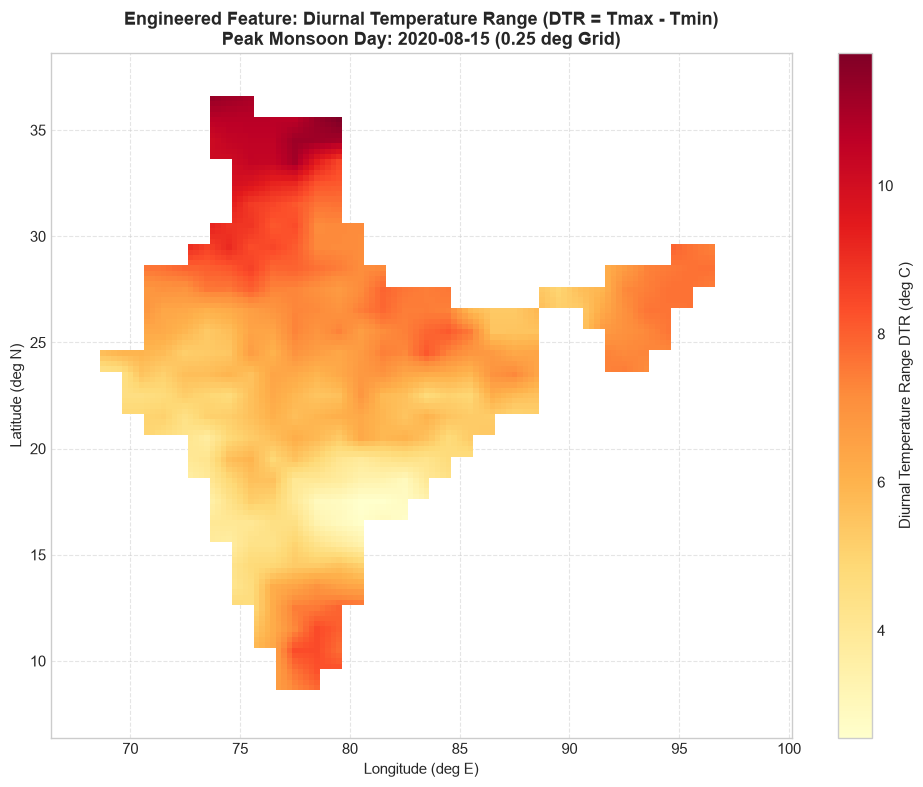

In [28]:
# Execute main pipeline and inspect output NetCDF datasets
pipeline_result = run_preprocessing_pipeline(
    year=2020,
    save_netcdf=True,
    normalize=True
)

print('\n=== PIPELINE VERIFICATION SUMMARY ===')
print('Pipeline Status:', pipeline_result['pipeline_status'])
print('Aligned NetCDF Output Path:', pipeline_result['output_path'])
print('Normalized NetCDF Output Path:', pipeline_result['normalized_output_path'])
print('Saved Joblib Scaler Registry:', pipeline_result['scaler_registry_path'])

# Open and inspect the generated NetCDF file directly from disk
processed_nc = xr.open_dataset(pipeline_result['output_path'])
print('\n=== PROCESSED NETCDF DATASET STRUCTURE ===')
display(processed_nc)

# Plot sample 2D spatial heatmap of derived feature DTR (Diurnal Temperature Range)
target_day_idx = 227  # Aug 15, 2020
target_date = str(pd.to_datetime(processed_nc.coords['time'].values[target_day_idx]).date())
dtr_2d = processed_nc['dtr'].values[target_day_idx, :, :]

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.pcolormesh(processed_nc.coords['lon'].values, processed_nc.coords['lat'].values, dtr_2d, cmap='YlOrRd', shading='auto')
cbar = plt.colorbar(im, ax=ax, label='Diurnal Temperature Range DTR (deg C)')
ax.set_title(f'Engineered Feature: Diurnal Temperature Range (DTR = Tmax - Tmin)\nPeak Monsoon Day: {target_date} (0.25 deg Grid)', fontweight='bold')
ax.set_xlabel('Longitude (deg E)')
ax.set_ylabel('Latitude (deg N)')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
plt.close('all')

processed_nc.close()